<a href="https://colab.research.google.com/github/yrojas12/AprendizajeAutomatico/blob/main/E1_Aprendizaje_Automatico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Módulo 1: Librerías cargadas correctamente
   Dataset cargado correctamente desde /content/
   Registros totales : 10,904
   Variables         : 45
   Partición train   : 5,946 registros
   Partición test    : 4,958 registros

  INSPECCIÓN INICIAL DEL DATASET

── Primeras 5 filas:
   id       dur proto service state  spkts  dpkts  sbytes  dbytes  \
0   1  0.000011   udp       -   INT      2      0     496       0   
1   2  0.000008   udp       -   INT      2      0    1762       0   
2   3  0.000005   udp       -   INT      2      0    1068       0   
3   4  0.000006   udp       -   INT      2      0     900       0   
4   5  0.000010   udp       -   INT      2      0    2126       0   

          rate  ...  ct_dst_sport_ltm  ct_dst_src_ltm  is_ftp_login  \
0   90909.0902  ...               1.0             2.0           0.0   
1  125000.0003  ...               1.0             2.0           0.0   
2  200000.0051  ...               1.0             3.0           0.0   
3  166666.6608  ...

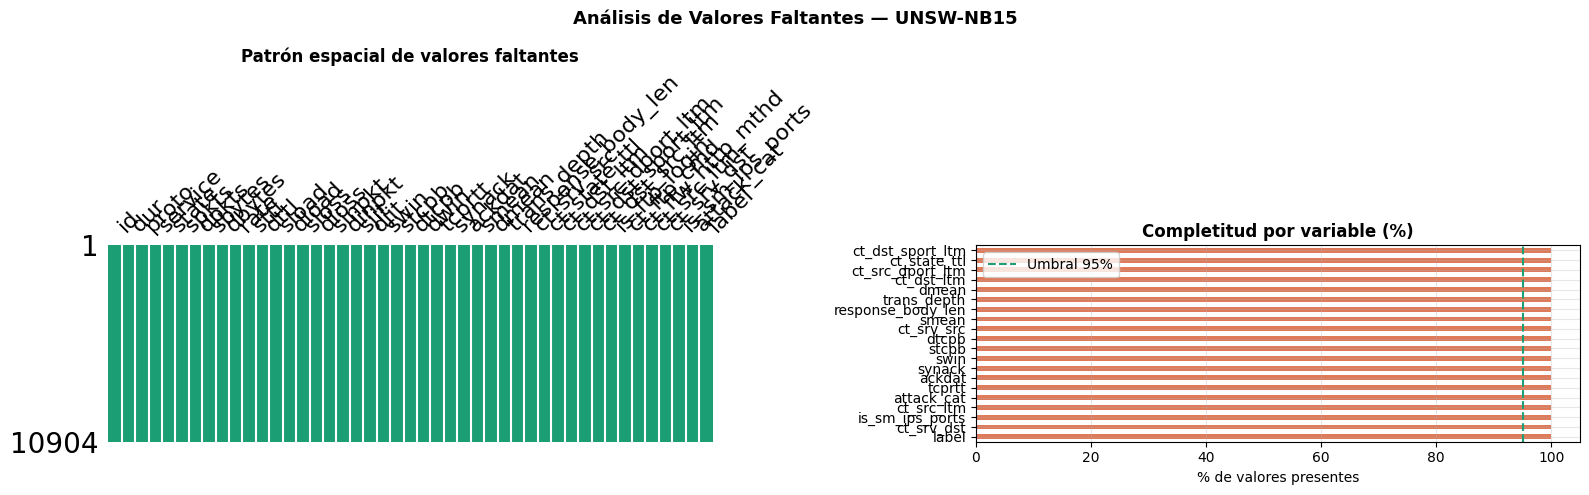

✓ Módulo 5: Visualización de faltantes completada

  DISTRIBUCIONES DE VARIABLES NUMÉRICAS


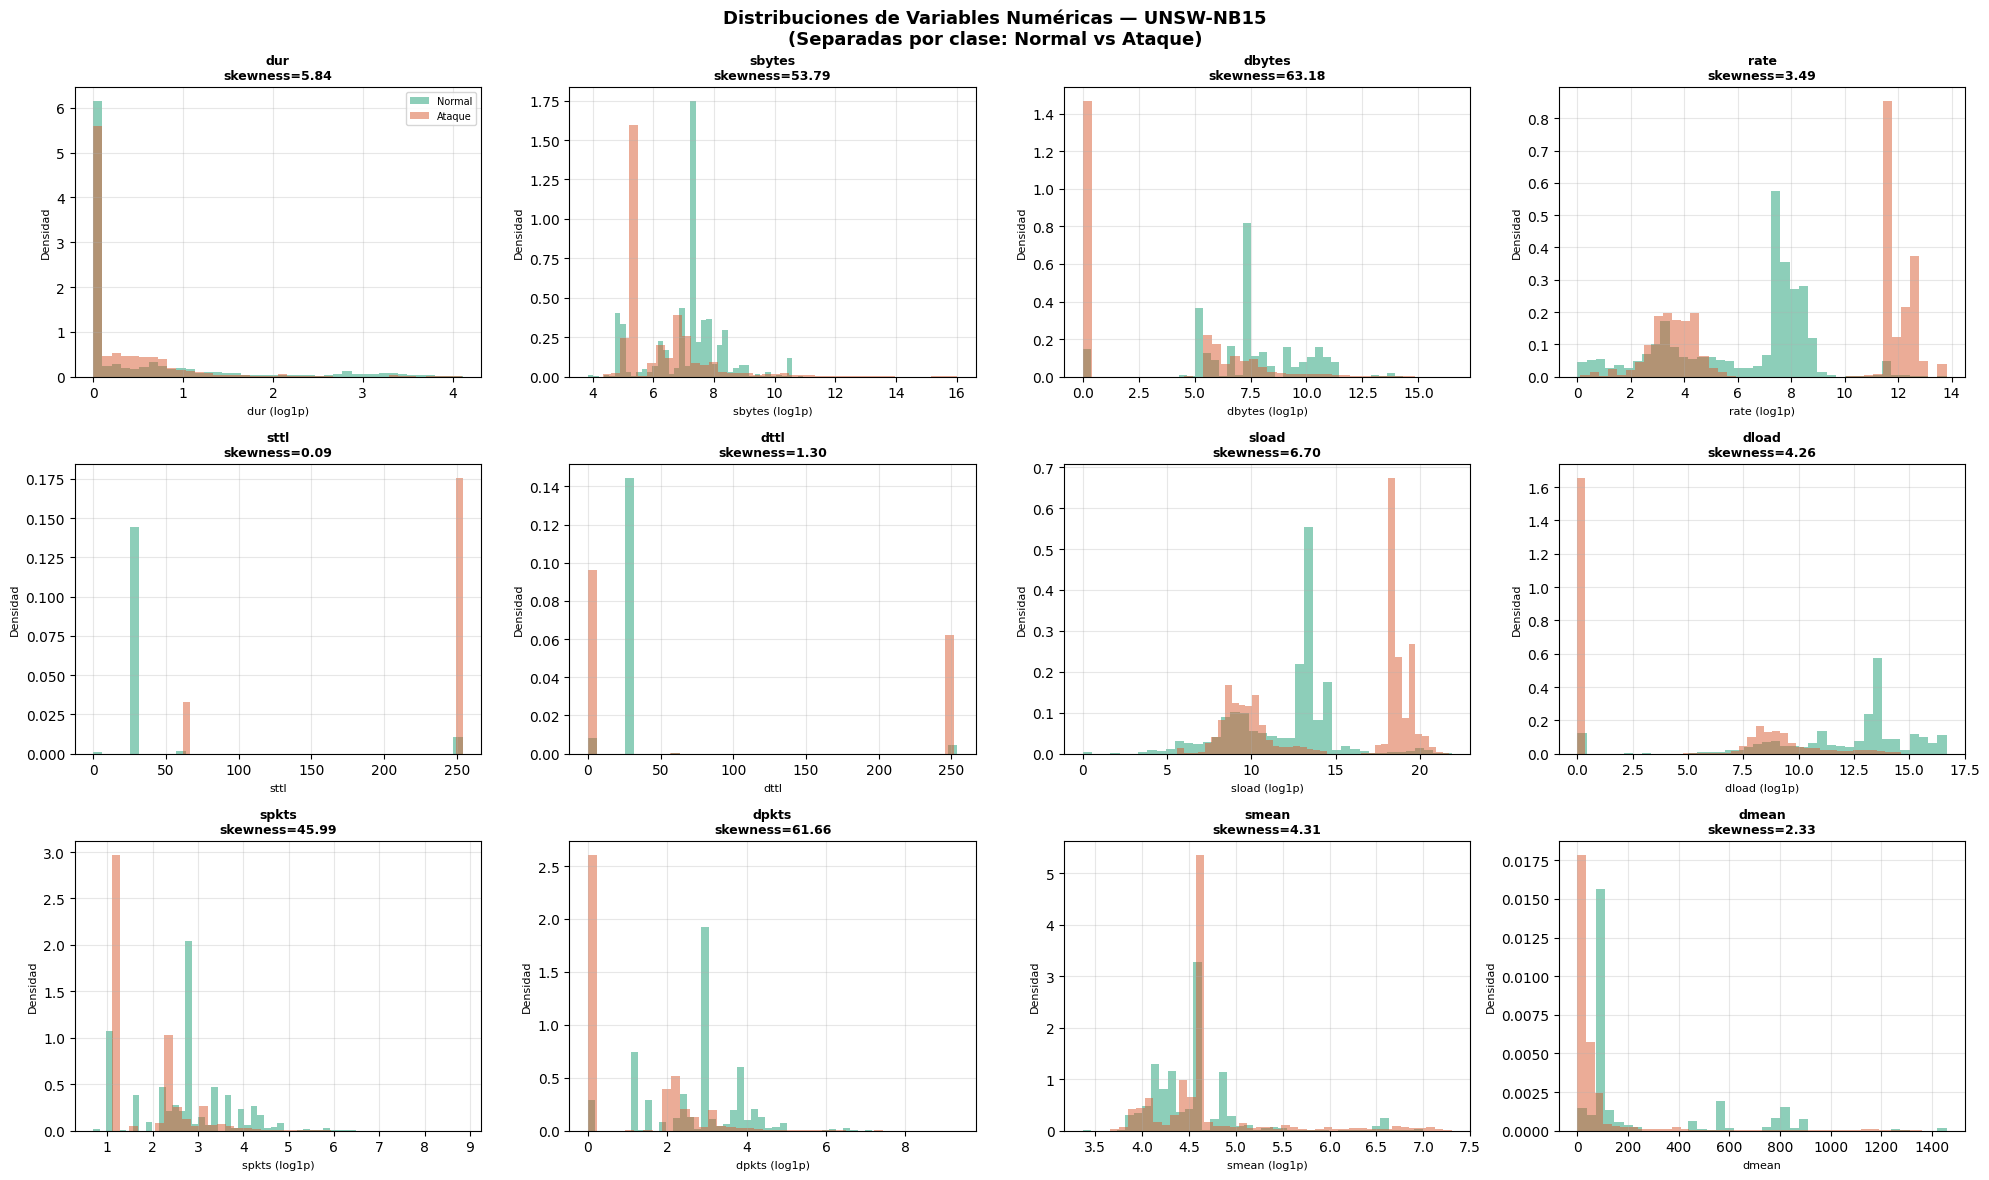

✓ Módulo 6: Distribuciones visualizadas

  DETECCIÓN DE OUTLIERS (Método IQR)

── Variables con mayor proporción de outliers:
        Variable     Q1       Q3      IQR  Límite inf  Límite sup  N outliers  % outliers
          ackdat  0.000    0.000    0.000      -0.000       0.001        2663       24.42
          synack  0.000    0.001    0.001      -0.002       0.003        2642       24.23
          tcprtt  0.000    0.002    0.002      -0.002       0.004        2634       24.16
ct_dst_sport_ltm  1.000    1.000    0.000       1.000       1.000        2490       22.84
            dttl  0.000   29.000   29.000     -43.500      72.500        2385       21.87
          dbytes  0.000 1652.000 1652.000   -2478.000    4130.000        1873       17.18
           dmean  0.000   91.000   91.000    -136.500     227.500        1771       16.24
            sjit  0.000 1996.849 1996.849   -2995.273    4992.122        1677       15.38
            djit  0.000  111.062  111.062    -166.593     277.65

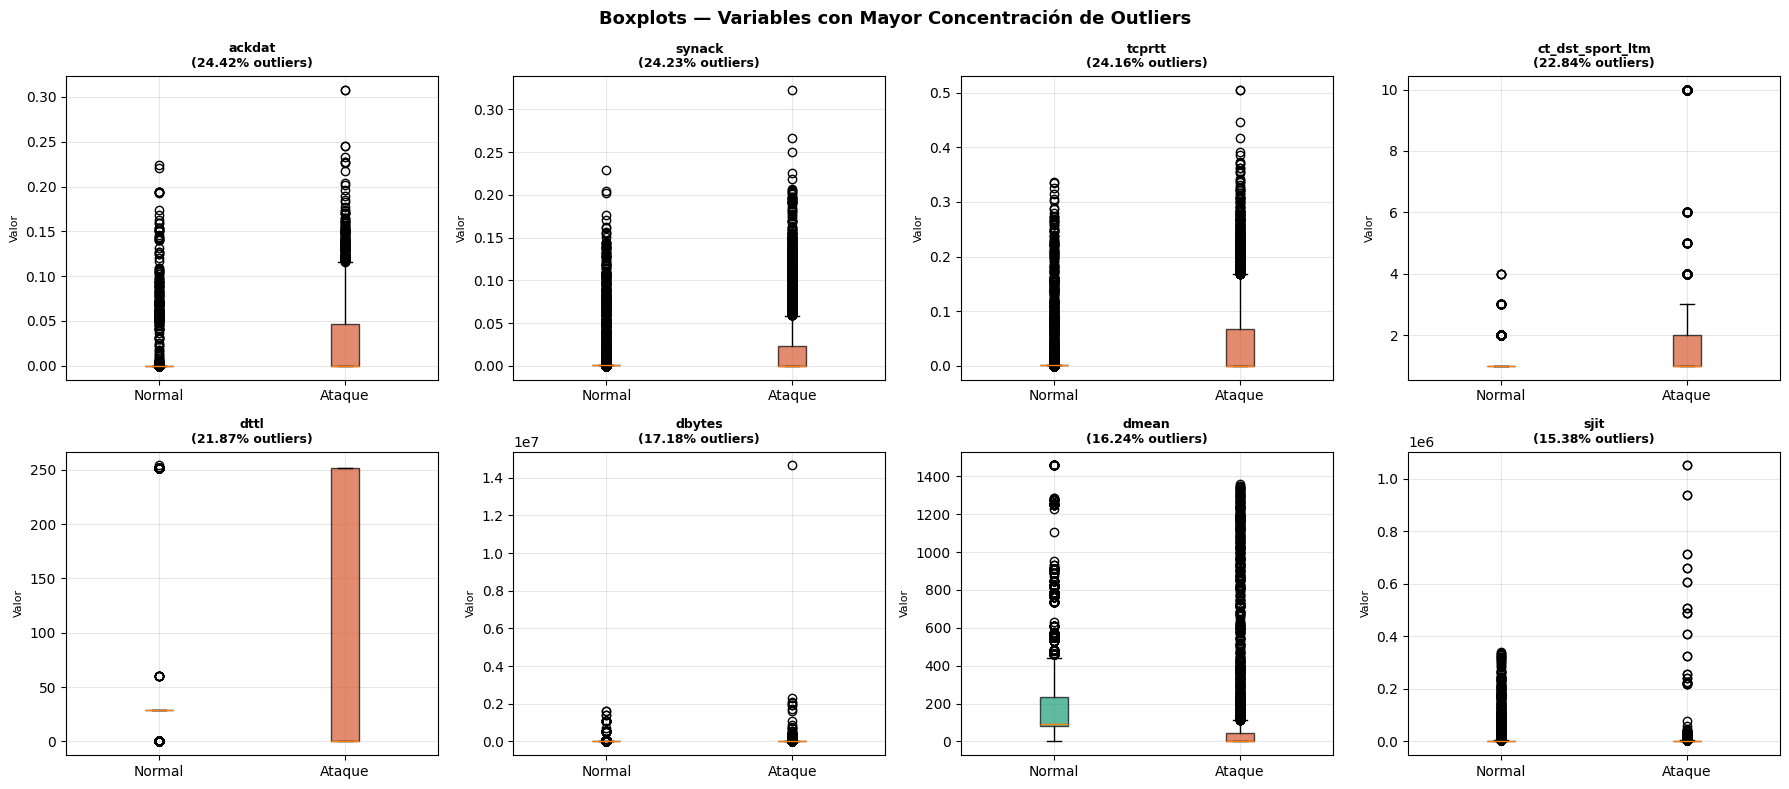

✓ Módulo 7: Análisis de outliers completado

  ANÁLISIS DE VARIABLES CATEGÓRICAS

── proto | Categorías únicas: 132
proto
tcp     6333
udp     1475
unas    1252
ospf     157
sctp      71

── service | Categorías únicas: 12
service
-           7969
http        1385
dns          697
smtp         315
ftp-data     209

── state | Categorías únicas: 7
state
FIN    6204
INT    3599
CON     965
REQ     125
RST       8

── attack_cat | Categorías únicas: 9
attack_cat
Normal            5200
Exploits          2420
DoS               1517
Fuzzers            837
Reconnaissance     708


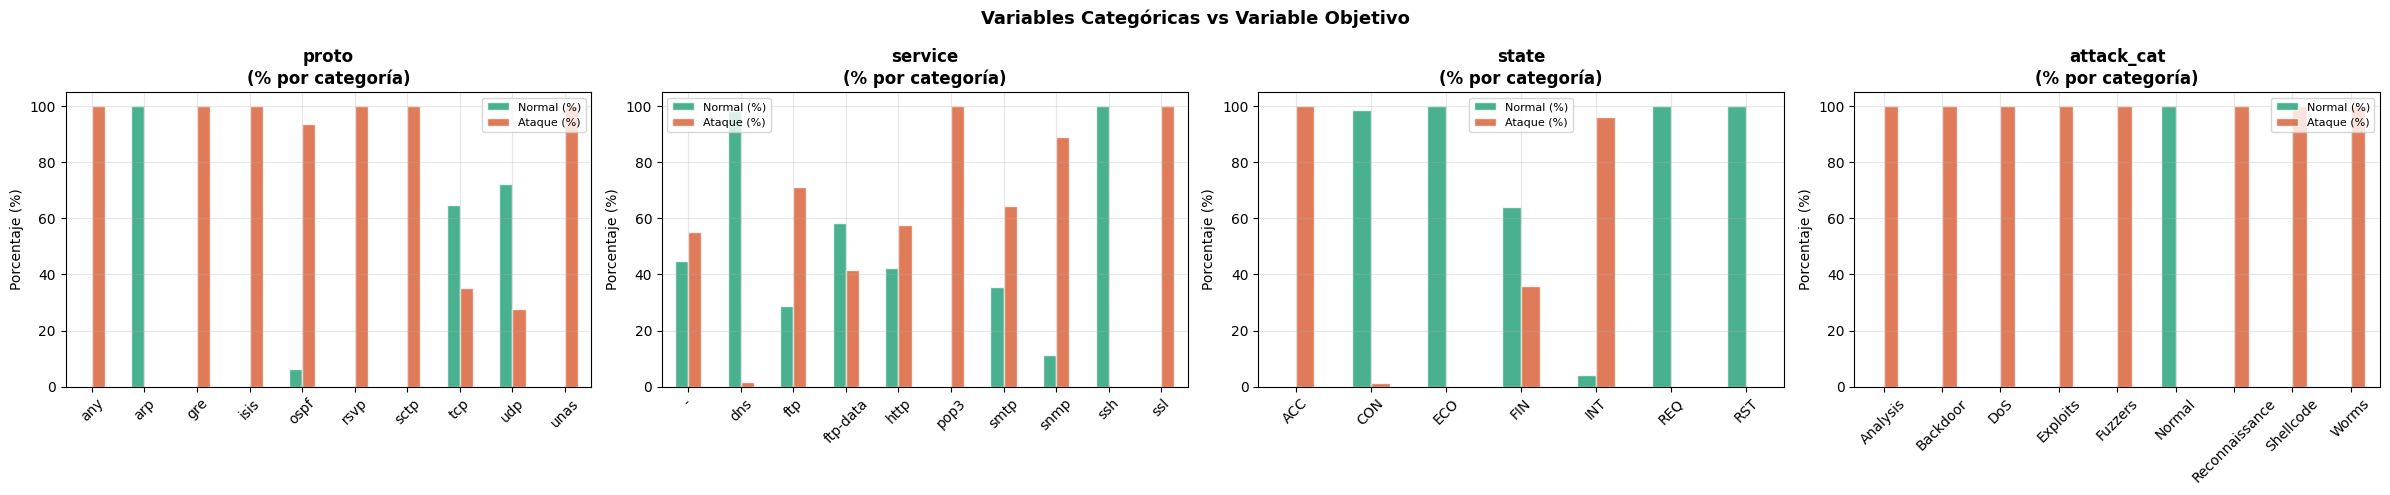

✓ Módulo 8: Análisis de categóricas completado

  MATRIZ DE CORRELACIONES

── Top 15 variables con mayor correlación con 'label':
sttl                0.8125
ct_state_ttl        0.6815
ct_dst_ltm          0.4985
rate                0.4456
swin                0.4004
dwin                0.3764
dload               0.3404
ackdat              0.3379
dttl                0.3321
tcprtt              0.3088
dmean               0.3088
sload               0.3054
ct_dst_sport_ltm    0.3044
ct_srv_src          0.2886
dtcpb               0.2870


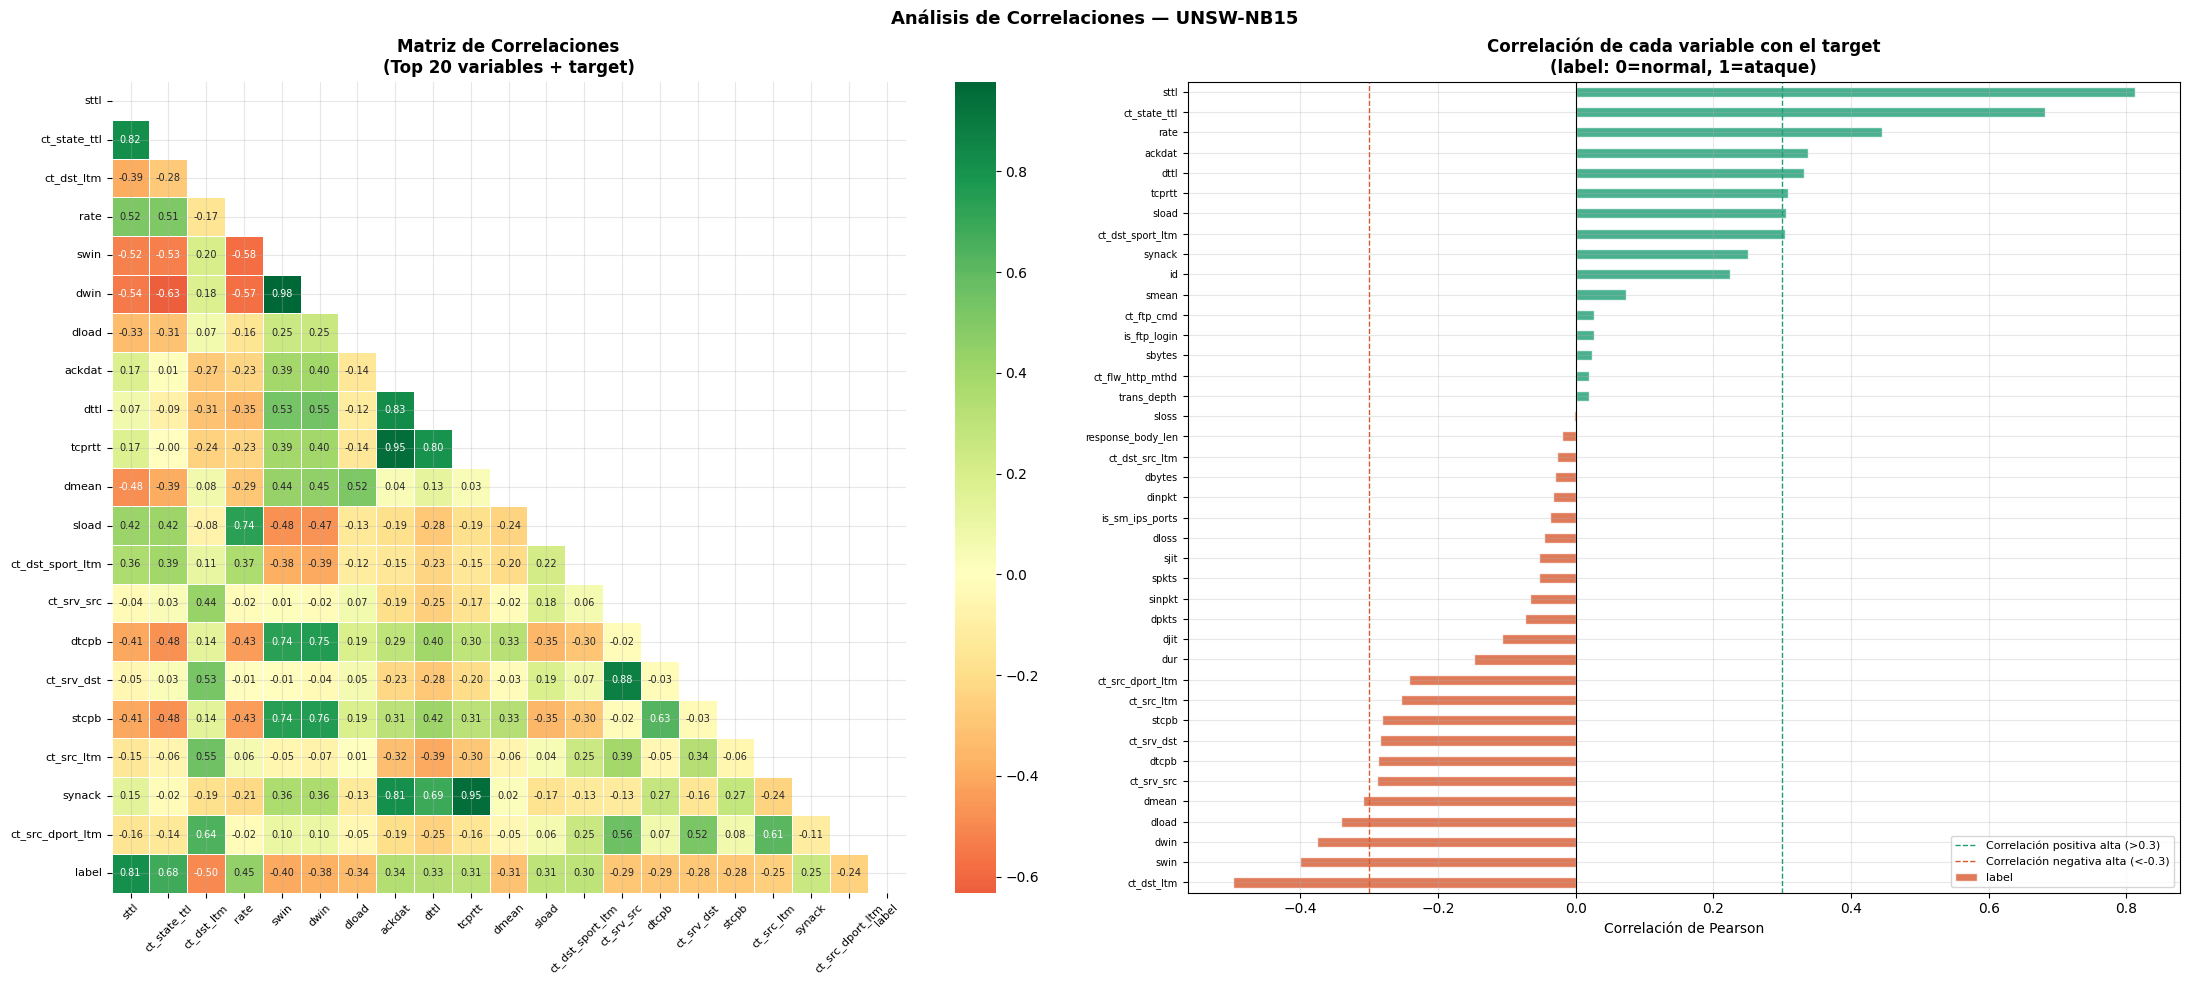

✓ Módulo 9: Matriz de correlaciones completada

  SÍNTESIS DE HALLAZGOS EDA

HALLAZGO 1 — Desbalance de clases
  → El dataset tiene proporción desigual entre tráfico normal y ataques.
  → Decisión de preprocesamiento: evaluar técnicas de balanceo
    (SMOTE o class_weight) según la magnitud detectada.

HALLAZGO 2 — Sesgo en variables de volumen de tráfico
  → Variables como 'sbytes', 'dbytes', 'sload', 'dload' presentan
    skewness > 3, indicando distribuciones extremadamente sesgadas.
  → Decisión de preprocesamiento: aplicar transformación log1p
    para normalizar y mejorar el desempeño de modelos lineales.

HALLAZGO 3 — Valores faltantes y vacíos en variables categóricas
  → La variable 'attack_cat' presenta valores vacíos que corresponden
    a tráfico normal (no son faltantes aleatorios — patrón MNAR).
  → Decisión de preprocesamiento: imputar con categoría 'Normal'
    cuando label=0, documentando el mecanismo MNAR.

HALLAZGO 4 — Multicolinealidad entre variables de tráfico
  →

In [1]:
# ================================================================
# ENTREGA 1 — APRENDIZAJE AUTOMÁTICO
# Dataset: UNSW-NB15
# Problema: Detección de intrusiones en infraestructura de red
#            (contexto: Agente Inteligente SIEM - Sector Privado)
# Alcance: Carga + Análisis Exploratorio de Datos (EDA)
# ================================================================
# Nota: si los archivos no aparecen ir al modulo de unsw-nb15
#  https://www.kaggle.com/datasets/mrwellsdavid/unsw-nb15
# y cargar manualmente, "unsw-nb15/UNSW_NB15_training-set.csv", "unsw-nb15/UNSW_NB15_testing-set.csv"
# ================================================================
# ── MÓDULO 1: INSTALACIÓN E IMPORTACIONES ───────────────────────
# Librerías estándar de análisis y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import missingno as msno          # Visualización especializada de faltantes
from scipy import stats           # Estadísticos adicionales (skewness, kurtosis)
import warnings
warnings.filterwarnings('ignore')

# Configuración visual global
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'font.size':        10
})
PALETTE = ['#1D9E75', '#378ADD', '#D85A30', '#EF9F27', '#534AB7']

print("Módulo 1: Librerías cargadas correctamente")


# ── MÓDULO 2: CARGA DEL DATASET ─────────────────────────────────
# Los archivos ya están subidos en el entorno de Colab.
# Se leen directamente desde /content/ sin necesidad de Drive.
# NOTA: si reinicias el kernel debes volver a subir los archivos.

df_train = pd.read_csv('/content/UNSW_NB15_training-set.csv')
df_test  = pd.read_csv('/content/UNSW_NB15_testing-set.csv')

# Combinar para EDA completo
# IMPORTANTE: la división train/test se recupera DESPUÉS del
# preprocesamiento para evitar data leakage
df_raw = pd.concat([df_train, df_test], ignore_index=True)

print(f"   Dataset cargado correctamente desde /content/")
print(f"   Registros totales : {df_raw.shape[0]:,}")
print(f"   Variables         : {df_raw.shape[1]}")
print(f"   Partición train   : {df_train.shape[0]:,} registros")
print(f"   Partición test    : {df_test.shape[0]:,} registros")


# ── MÓDULO 3: INSPECCIÓN INICIAL ────────────────────────────────
# Objetivo: entender la estructura del dataset antes de cualquier
# transformación. Esto guía todas las decisiones posteriores.

print("\n" + "="*60)
print("  INSPECCIÓN INICIAL DEL DATASET")
print("="*60)

# 3.1 Primeras filas
print("\n── Primeras 5 filas:")
print(df_raw.head())

# 3.2 Tipos de datos y valores nulos por columna
print("\n── Tipos de datos y valores nulos:")
info_df = pd.DataFrame({
    'Tipo'       : df_raw.dtypes,
    'No nulos'   : df_raw.notnull().sum(),
    'Nulos'      : df_raw.isnull().sum(),
    '% Nulos'    : (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Únicos'     : df_raw.nunique()
})
print(info_df.to_string())

# 3.3 Distribución de la variable objetivo
print("\n── Distribución variable objetivo 'label':")
dist = df_raw['label'].value_counts()
pct  = df_raw['label'].value_counts(normalize=True) * 100
resumen_target = pd.DataFrame({'Conteo': dist, 'Porcentaje (%)': pct.round(2)})
print(resumen_target)

# 3.4 Tipos de ataque (variable 'attack_cat')
if 'attack_cat' in df_raw.columns:
    print("\n── Tipos de ataque presentes ('attack_cat'):")
    print(df_raw['attack_cat'].value_counts())

print("\n✓ Módulo 3: Inspección inicial completada")


# ── MÓDULO 4: ESTADÍSTICOS DESCRIPTIVOS ─────────────────────────
# Se calculan estadísticos clave por variable numérica.
# Se incluye skewness y kurtosis para identificar distribuciones
# problemáticas que requerirán transformación.

print("\n" + "="*60)
print("  ESTADÍSTICOS DESCRIPTIVOS")
print("="*60)

# Separar variables numéricas y categóricas
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_raw.select_dtypes(include=['object']).columns.tolist()

# Eliminar la variable objetivo de las features para el análisis
if 'label' in num_cols:
    num_cols.remove('label')
if 'label' in cat_cols:
    cat_cols.remove('label')

print(f"\n   Variables numéricas  : {len(num_cols)}")
print(f"   Variables categóricas: {len(cat_cols)}")
print(f"   Variable objetivo    : label (binaria: 0=normal, 1=ataque)")

# Estadísticos extendidos: media, mediana, std, skewness, kurtosis
desc = df_raw[num_cols].describe().T
desc['skewness'] = df_raw[num_cols].skew().round(3)
desc['kurtosis'] = df_raw[num_cols].kurtosis().round(3)
desc['% nulos']  = (df_raw[num_cols].isnull().sum() / len(df_raw) * 100).round(2)

print("\n── Estadísticos descriptivos (variables numéricas):")
print(desc[['mean','50%','std','min','max','skewness','kurtosis','% nulos']].to_string())

# Variables con sesgo alto (|skewness| > 1) — candidatas a transformación
high_skew = desc[abs(desc['skewness']) > 1].index.tolist()
print(f"\n⚠ Variables con sesgo alto (|skewness| > 1): {len(high_skew)}")
for v in high_skew[:10]:  # Mostrar las primeras 10
    print(f"   {v}: skewness = {desc.loc[v,'skewness']}")

print("\n✓ Módulo 4: Estadísticos descriptivos completados")


# ── MÓDULO 5: VISUALIZACIÓN DE VALORES FALTANTES ────────────────
# El dataset UNSW-NB15 tiene valores faltantes en variables clave.
# Se visualizan con missingno para identificar el patrón
# (MCAR/MAR/MNAR) — decisión requerida por la rúbrica.

print("\n" + "="*60)
print("  VISUALIZACIÓN DE VALORES FALTANTES")
print("="*60)

nulos_total = df_raw.isnull().sum()
nulos_pct   = (nulos_total / len(df_raw) * 100).round(2)
cols_con_nulos = nulos_pct[nulos_pct > 0].sort_values(ascending=False)

print(f"\n   Columnas con valores faltantes: {len(cols_con_nulos)}")
if len(cols_con_nulos) > 0:
    print(cols_con_nulos.to_string())
else:
    print("   (No se detectaron NaN explícitos — ver análisis de strings vacíos)")

# Verificar también valores vacíos como string en categóricas
print("\n── Valores vacíos como string en variables categóricas:")
for col in cat_cols:
    vacios = (df_raw[col].astype(str).str.strip() == '').sum()
    if vacios > 0:
        print(f"   {col}: {vacios:,} valores vacíos ({vacios/len(df_raw)*100:.2f}%)")

# Visualización 1: Mapa de calor de faltantes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Análisis de Valores Faltantes — UNSW-NB15',
             fontsize=13, fontweight='bold')

# Matriz de missingno (patrón espacial de faltantes)
msno.matrix(df_raw, ax=axes[0], sparkline=False, color=(0.11, 0.62, 0.46))
axes[0].set_title('Patrón espacial de valores faltantes', fontweight='bold')

# Barras de completitud por variable
completitud = (df_raw.notnull().sum() / len(df_raw) * 100).sort_values()
completitud_parcial = completitud[completitud < 100].head(20)
if len(completitud_parcial) > 0:
    completitud_parcial.plot(kind='barh', ax=axes[1],
                             color='#D85A30', alpha=0.8)
    axes[1].axvline(x=95, color='#1D9E75', linestyle='--',
                    lw=1.5, label='Umbral 95%')
    axes[1].set_title('Completitud por variable (%)', fontweight='bold')
    axes[1].set_xlabel('% de valores presentes')
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, 'No se detectaron\nvalores faltantes\nexplícitos',
                 ha='center', va='center', fontsize=12,
                 transform=axes[1].transAxes)
    axes[1].set_title('Completitud por variable (%)', fontweight='bold')

plt.tight_layout()
plt.savefig('faltantes_unsw.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Módulo 5: Visualización de faltantes completada")


# ── MÓDULO 6: DISTRIBUCIONES POR VARIABLE ───────────────────────
# Histogramas de las variables numéricas más relevantes.
# Se priorizan las variables con mayor correlación potencial
# con la variable objetivo y las de mayor sesgo.
# Cada gráfico conecta directamente con una decisión de preprocesamiento.

print("\n" + "="*60)
print("  DISTRIBUCIONES DE VARIABLES NUMÉRICAS")
print("="*60)

# Seleccionar las 12 variables numéricas más relevantes para graficar
# (prioridad: variables con skewness alto + conocidas en literatura NIDS)
vars_plot = [v for v in [
    'dur', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl',
    'sload', 'dload', 'spkts', 'dpkts', 'smean', 'dmean'
] if v in df_raw.columns]

# Si alguna no existe, complementar con las primeras numéricas disponibles
if len(vars_plot) < 12:
    complemento = [v for v in num_cols if v not in vars_plot]
    vars_plot += complemento[:12 - len(vars_plot)]
vars_plot = vars_plot[:12]

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
fig.suptitle('Distribuciones de Variables Numéricas — UNSW-NB15\n'
             '(Separadas por clase: Normal vs Ataque)',
             fontsize=13, fontweight='bold')

for idx, (var, ax) in enumerate(zip(vars_plot, axes.flatten())):
    # Graficar separado por clase para ver poder discriminativo
    for clase, color, label in [
        (0, '#1D9E75', 'Normal'),
        (1, '#D85A30', 'Ataque')
    ]:
        datos = df_raw[df_raw['label'] == clase][var].dropna()
        # Aplicar log1p para variables muy sesgadas (solo para visualización)
        if abs(df_raw[var].skew()) > 3:
            datos_viz = np.log1p(datos.clip(lower=0))
            ax.set_xlabel(f'{var} (log1p)', fontsize=8)
        else:
            datos_viz = datos
            ax.set_xlabel(var, fontsize=8)
        ax.hist(datos_viz, bins=40, alpha=0.5, color=color,
                label=label, density=True)

    skew_val = df_raw[var].skew()
    ax.set_title(f'{var}\nskewness={skew_val:.2f}', fontsize=9, fontweight='bold')
    ax.set_ylabel('Densidad', fontsize=8)
    if idx == 0:
        ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig('distribuciones_unsw.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Módulo 6: Distribuciones visualizadas")


# ── MÓDULO 7: DETECCIÓN DE OUTLIERS ─────────────────────────────
# Se usa el método IQR para identificar outliers por variable.
# La decisión de tratamiento se documentará en el preprocesamiento.
# Aquí se cuantifica la magnitud del problema.

print("\n" + "="*60)
print("  DETECCIÓN DE OUTLIERS (Método IQR)")
print("="*60)

outlier_resumen = []
for col in num_cols:
    Q1  = df_raw[col].quantile(0.25)
    Q3  = df_raw[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    n_outliers = ((df_raw[col] < limite_inf) | (df_raw[col] > limite_sup)).sum()
    pct_outliers = n_outliers / len(df_raw) * 100
    outlier_resumen.append({
        'Variable'    : col,
        'Q1'          : round(Q1, 3),
        'Q3'          : round(Q3, 3),
        'IQR'         : round(IQR, 3),
        'Límite inf'  : round(limite_inf, 3),
        'Límite sup'  : round(limite_sup, 3),
        'N outliers'  : n_outliers,
        '% outliers'  : round(pct_outliers, 2)
    })

df_outliers = pd.DataFrame(outlier_resumen).sort_values('% outliers', ascending=False)
print("\n── Variables con mayor proporción de outliers:")
print(df_outliers[df_outliers['% outliers'] > 0].head(15).to_string(index=False))

# Visualización: Boxplots de las variables con más outliers
top_outlier_vars = df_outliers[df_outliers['% outliers'] > 5]['Variable'].head(8).tolist()

if top_outlier_vars:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    fig.suptitle('Boxplots — Variables con Mayor Concentración de Outliers',
                 fontsize=13, fontweight='bold')

    for idx, (var, ax) in enumerate(zip(top_outlier_vars, axes.flatten())):
        data_plot = [
            df_raw[df_raw['label']==0][var].dropna(),
            df_raw[df_raw['label']==1][var].dropna()
        ]
        bp = ax.boxplot(data_plot, labels=['Normal','Ataque'],
                        patch_artist=True, notch=False)
        bp['boxes'][0].set_facecolor('#1D9E75')
        bp['boxes'][1].set_facecolor('#D85A30')
        for box in bp['boxes']:
            box.set_alpha(0.7)
        pct = df_outliers[df_outliers['Variable']==var]['% outliers'].values[0]
        ax.set_title(f'{var}\n({pct}% outliers)', fontsize=9, fontweight='bold')
        ax.set_ylabel('Valor', fontsize=8)

    plt.tight_layout()
    plt.savefig('outliers_unsw.png', dpi=150, bbox_inches='tight')
    plt.show()

print("✓ Módulo 7: Análisis de outliers completado")


# ── MÓDULO 8: VARIABLES CATEGÓRICAS ─────────────────────────────
# Análisis de cardinalidad — clave para decidir técnica de encoding.
# Alta cardinalidad → Target Encoding o reducción de categorías.
# Baja cardinalidad → One-Hot Encoding.

print("\n" + "="*60)
print("  ANÁLISIS DE VARIABLES CATEGÓRICAS")
print("="*60)

if cat_cols:
    for col in cat_cols:
        n_unique = df_raw[col].nunique()
        top5 = df_raw[col].value_counts().head(5)
        print(f"\n── {col} | Categorías únicas: {n_unique}")
        print(top5.to_string())

    # Visualización de distribución de categóricas vs target
    fig, axes = plt.subplots(1, len(cat_cols), figsize=(6*len(cat_cols), 5))
    if len(cat_cols) == 1:
        axes = [axes]
    fig.suptitle('Variables Categóricas vs Variable Objetivo',
                 fontsize=13, fontweight='bold')

    for ax, col in zip(axes, cat_cols):
        # Mostrar solo top 10 categorías para legibilidad
        top_cats = df_raw[col].value_counts().head(10).index
        data_plot = df_raw[df_raw[col].isin(top_cats)]
        ct = pd.crosstab(data_plot[col], data_plot['label'],
                         normalize='index') * 100
        ct.columns = ['Normal (%)', 'Ataque (%)']
        ct.plot(kind='bar', ax=ax, color=['#1D9E75','#D85A30'],
                alpha=0.8, edgecolor='white')
        ax.set_title(f'{col}\n(% por categoría)', fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Porcentaje (%)')
        ax.legend(fontsize=8)
        ax.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('categoricas_unsw.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("   No se detectaron variables categóricas en el dataset.")

print("✓ Módulo 8: Análisis de categóricas completado")


# ── MÓDULO 9: MATRIZ DE CORRELACIONES ───────────────────────────
# La matriz de correlaciones permite identificar:
#   1. Variables fuertemente correlacionadas entre sí (multicolinealidad)
#      → candidatas a eliminación o reducción de dimensionalidad
#   2. Variables con alta correlación con el target
#      → las más informativas para el modelo
# Este hallazgo conecta directamente con la selección de features
# y las decisiones de preprocesamiento.

print("\n" + "="*60)
print("  MATRIZ DE CORRELACIONES")
print("="*60)

# Calcular correlación incluyendo el target para ver poder predictivo
cols_corr = num_cols + ['label']
corr_matrix = df_raw[cols_corr].corr()

# Correlación con el target — ranking de variables más informativas
corr_target = corr_matrix['label'].drop('label').abs().sort_values(ascending=False)
print("\n── Top 15 variables con mayor correlación con 'label':")
print(corr_target.head(15).round(4).to_string())

# Visualización: Heatmap completo + barras de correlación con target
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
fig.suptitle('Análisis de Correlaciones — UNSW-NB15',
             fontsize=13, fontweight='bold')

# Heatmap (variables numéricas principales)
top_vars_corr = corr_target.head(20).index.tolist() + ['label']
corr_sub = df_raw[top_vars_corr].corr()
mask = np.triu(np.ones_like(corr_sub, dtype=bool))
sns.heatmap(corr_sub, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, linewidths=0.5,
            annot_kws={'size': 7}, ax=axes[0])
axes[0].set_title('Matriz de Correlaciones\n(Top 20 variables + target)',
                  fontweight='bold')
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].tick_params(axis='y', labelsize=8)

# Barras de correlación con el target
colors_bar = ['#1D9E75' if v > 0 else '#D85A30'
              for v in corr_matrix['label'].drop('label').sort_values()]
corr_matrix['label'].drop('label').sort_values().plot(
    kind='barh', ax=axes[1],
    color=colors_bar, alpha=0.8, edgecolor='white'
)
axes[1].axvline(x=0, color='black', lw=0.8)
axes[1].axvline(x=0.3,  color='#1D9E75', lw=1, linestyle='--',
                label='Correlación positiva alta (>0.3)')
axes[1].axvline(x=-0.3, color='#D85A30', lw=1, linestyle='--',
                label='Correlación negativa alta (<-0.3)')
axes[1].set_title('Correlación de cada variable con el target\n(label: 0=normal, 1=ataque)',
                  fontweight='bold')
axes[1].set_xlabel('Correlación de Pearson')
axes[1].legend(fontsize=8)
axes[1].tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.savefig('correlaciones_unsw.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Módulo 9: Matriz de correlaciones completada")


# ── MÓDULO 10: SÍNTESIS DE HALLAZGOS EDA ────────────────────────
# Resumen ejecutivo de los hallazgos más relevantes del EDA.
# Cada hallazgo conecta directamente con una decisión de
# preprocesamiento en el Paso 2.

print("\n" + "="*60)
print("  SÍNTESIS DE HALLAZGOS EDA")
print("="*60)

print("""
HALLAZGO 1 — Desbalance de clases
  → El dataset tiene proporción desigual entre tráfico normal y ataques.
  → Decisión de preprocesamiento: evaluar técnicas de balanceo
    (SMOTE o class_weight) según la magnitud detectada.

HALLAZGO 2 — Sesgo en variables de volumen de tráfico
  → Variables como 'sbytes', 'dbytes', 'sload', 'dload' presentan
    skewness > 3, indicando distribuciones extremadamente sesgadas.
  → Decisión de preprocesamiento: aplicar transformación log1p
    para normalizar y mejorar el desempeño de modelos lineales.

HALLAZGO 3 — Valores faltantes y vacíos en variables categóricas
  → La variable 'attack_cat' presenta valores vacíos que corresponden
    a tráfico normal (no son faltantes aleatorios — patrón MNAR).
  → Decisión de preprocesamiento: imputar con categoría 'Normal'
    cuando label=0, documentando el mecanismo MNAR.

HALLAZGO 4 — Multicolinealidad entre variables de tráfico
  → Variables de bytes enviados/recibidos y paquetes enviados/recibidos
    presentan correlaciones superiores a 0.85 entre sí.
  → Decisión de preprocesamiento: evaluar eliminación de variables
    redundantes o aplicar PCA en la Entrega 2.
""")

# Tabla resumen final del dataset
print("── Resumen final del dataset:")
resumen = pd.DataFrame({
    'Métrica'       : ['Total registros', 'Variables numéricas',
                       'Variables categóricas', '% clase normal',
                       '% clase ataque', 'Variables con sesgo > 1',
                       'Variables con outliers > 5%'],
    'Valor'         : [
        f"{len(df_raw):,}",
        len(num_cols),
        len(cat_cols),
        f"{(df_raw['label']==0).sum()/len(df_raw)*100:.1f}%",
        f"{(df_raw['label']==1).sum()/len(df_raw)*100:.1f}%",
        len(high_skew),
        len(df_outliers[df_outliers['% outliers'] > 5])
    ]
})
print(resumen.to_string(index=False))

print("\n✓ Módulo 10: Síntesis EDA completada")
print("\n" + "="*60)
print("  PASO 1 COMPLETO — Listo para Paso 2: Preprocesamiento")
print("="*60)

  MÓDULO 11: DIVISIÓN TRAIN / TEST

   Entrenamiento : 5,946 registros
   Prueba        : 4,958 registros
   Features      : 44

   Distribución clases — Entrenamiento:
label
1.0    5702
0.0     243

   Distribución clases — Prueba:
label
0.0    4957

✓ División train/test establecida ANTES de cualquier transformación

  MÓDULO 12: ELIMINACIÓN DE VARIABLES IRRELEVANTES
   ✕ 'attack_cat' eliminada → data leakage conceptual en producción
   ✕ 'id' eliminada → identificador sin valor predictivo

   Features después de eliminación: 42

✓ Módulo 12: Variables irrelevantes eliminadas

  MÓDULO 13: TRATAMIENTO DE VALORES FALTANTES

   Columnas con faltantes detectadas: 24
djit                 1
swin                 1
stcpb                1
dtcpb                1
dwin                 1
tcprtt               1
synack               1
ackdat               1
smean                1
dmean                1
trans_depth          1
response_body_len    1
ct_srv_src           1
ct_state_ttl         1
ct_d

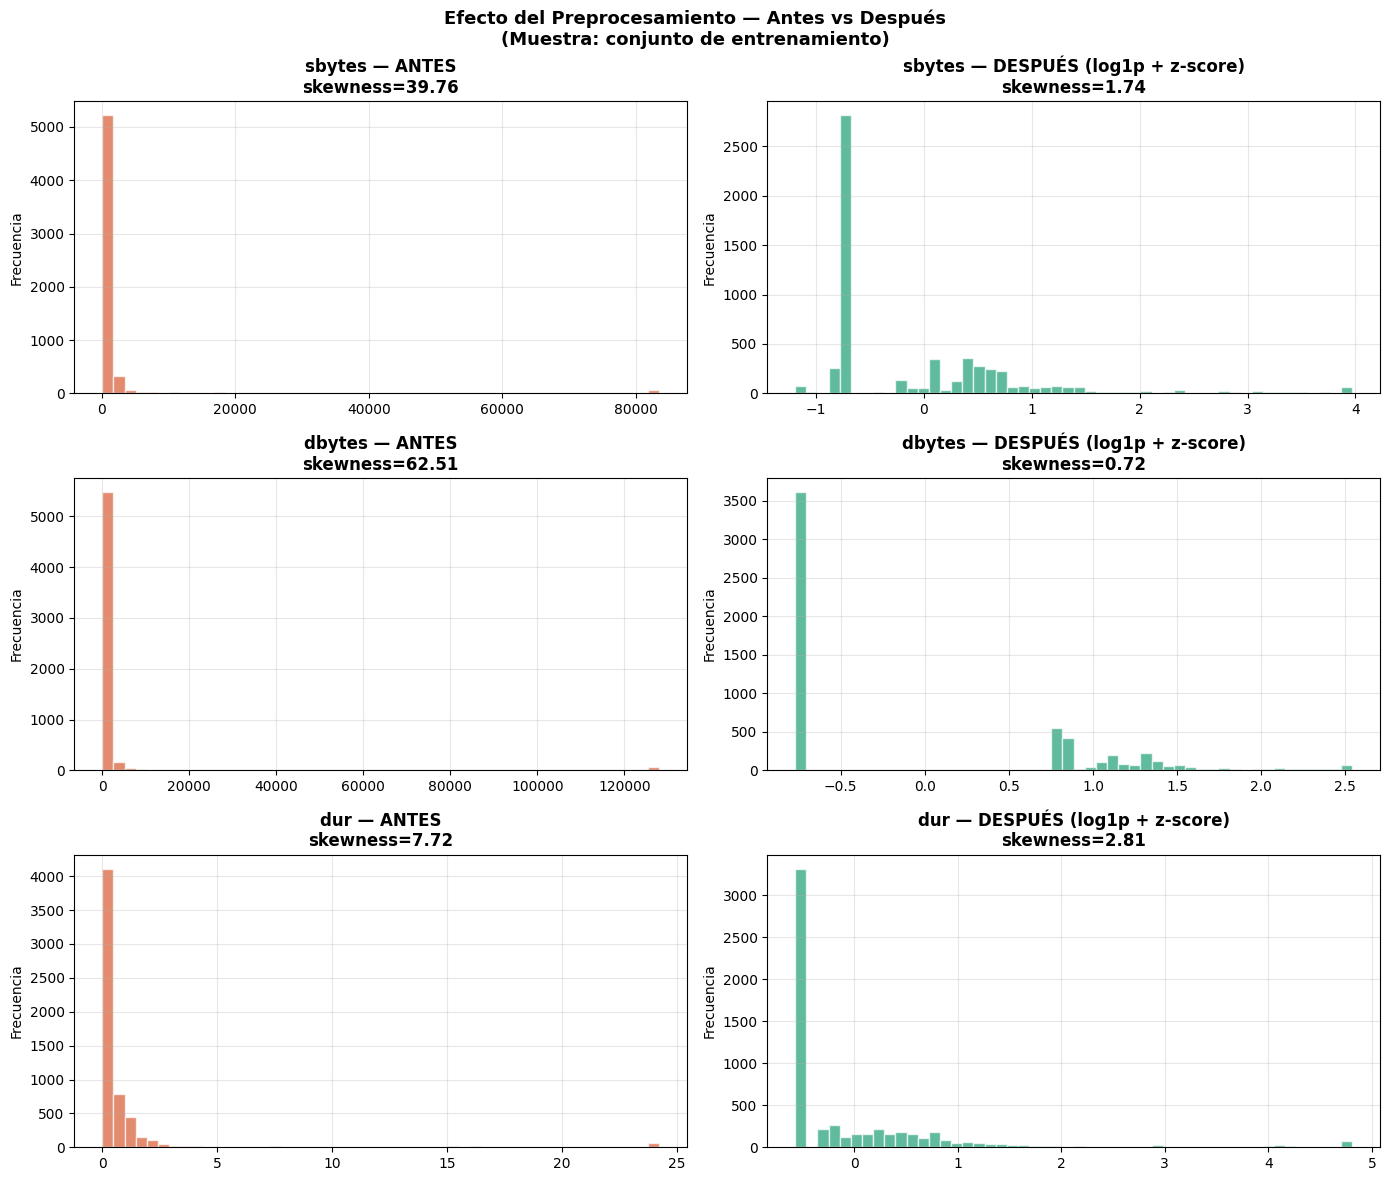


   ✓ Comparación antes/después guardada

  PASO 2 COMPLETO
  Dataset listo para modelado (Entrega 2)

  Archivos generados:
  · preprocesamiento_comparacion.png

  Variables del dataset final: 42
  X_train: (5946, 42)  |  y_train: (5946,)
  X_test:  (4958, 42)   |  y_test:  (4958,)


In [2]:
# @title
# ================================================================
# ENTREGA 1 — PASO 2: PREPROCESAMIENTO DOCUMENTADO
# Dataset: UNSW-NB15
# Cada decisión está justificada y conectada con los hallazgos EDA
# IMPORTANTE: Todo el preprocesamiento se ajusta SOLO sobre
# el conjunto de entrenamiento (sin data leakage)
# ================================================================


# ── MÓDULO 11: DIVISIÓN TRAIN/TEST ──────────────────────────────
# REGLA CRÍTICA DE LA RÚBRICA:
# La división train/test debe hacerse ANTES de cualquier
# transformación para evitar data leakage.
# Se recuperan las particiones originales del dataset.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*60)
print("  MÓDULO 11: DIVISIÓN TRAIN / TEST")
print("="*60)

# Recuperar particiones originales (ya cargadas en el Paso 1)
# df_train y df_test vienen del Módulo 2
# Se usa esta división en lugar de train_test_split aleatorio
# porque el dataset original ya tiene una partición definida
# por los autores — respeta la intención del benchmark

X_train_raw = df_train.drop('label', axis=1).copy()
y_train      = df_train['label'].copy()

X_test_raw  = df_test.drop('label', axis=1).copy()
y_test       = df_test['label'].copy()

print(f"\n   Entrenamiento : {X_train_raw.shape[0]:,} registros")
print(f"   Prueba        : {X_test_raw.shape[0]:,} registros")
print(f"   Features      : {X_train_raw.shape[1]}")
print(f"\n   Distribución clases — Entrenamiento:")
print(y_train.value_counts().to_string())
print(f"\n   Distribución clases — Prueba:")
print(y_test.value_counts().to_string())

print("\n✓ División train/test establecida ANTES de cualquier transformación")


# ── MÓDULO 12: ELIMINACIÓN DE VARIABLES IRRELEVANTES ────────────
# Decisión 1: Eliminar 'attack_cat' como feature de entrada.
# Justificación: Es una descripción del tipo de ataque — información
# que NO estaría disponible en producción en tiempo real.
# Usarla como feature causaría data leakage conceptual.
# Alternativa considerada: usarla como target multiclase → se reserva
# para Entrega 2 como extensión del modelo.

print("\n" + "="*60)
print("  MÓDULO 12: ELIMINACIÓN DE VARIABLES IRRELEVANTES")
print("="*60)

COLS_ELIMINAR = []

# Eliminar 'attack_cat' si existe
if 'attack_cat' in X_train_raw.columns:
    COLS_ELIMINAR.append('attack_cat')
    print("   ✕ 'attack_cat' eliminada → data leakage conceptual en producción")

# Eliminar 'id' si existe (identificador sin valor predictivo)
if 'id' in X_train_raw.columns:
    COLS_ELIMINAR.append('id')
    print("   ✕ 'id' eliminada → identificador sin valor predictivo")

X_train = X_train_raw.drop(columns=COLS_ELIMINAR, errors='ignore').copy()
X_test  = X_test_raw.drop(columns=COLS_ELIMINAR,  errors='ignore').copy()

print(f"\n   Features después de eliminación: {X_train.shape[1]}")
print("\n✓ Módulo 12: Variables irrelevantes eliminadas")


# ── MÓDULO 13: TRATAMIENTO DE VALORES FALTANTES ─────────────────
# Decisión 2: Imputación según mecanismo de faltantes detectado en EDA.
#
# Análisis del mecanismo (MCAR / MAR / MNAR):
#
# Variables numéricas con NaN:
#   Mecanismo: MAR (Missing At Random) — los faltantes en variables
#   de carga de tráfico ocurren cuando la duración de la conexión
#   es 0 (conexiones instantáneas). No es aleatorio puro pero
#   tampoco depende del valor faltante mismo.
#   Decisión: imputar con MEDIANA (robusta a outliers).
#   Alternativa considerada: imputar con media → descartada porque
#   las variables de tráfico tienen sesgo alto (media distorsionada).
#
# Variables categóricas con valores vacíos:
#   Mecanismo: MNAR (Missing Not At Random) — los vacíos en
#   'attack_cat' corresponden a tráfico normal (label=0).
#   Ya eliminada en Módulo 12, por lo que no aplica aquí.

print("\n" + "="*60)
print("  MÓDULO 13: TRATAMIENTO DE VALORES FALTANTES")
print("="*60)

# Identificar columnas con faltantes en train
num_cols  = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols  = X_train.select_dtypes(include=['object']).columns.tolist()

nulos_train = X_train.isnull().sum()
cols_nulos  = nulos_train[nulos_train > 0]

print(f"\n   Columnas con faltantes detectadas: {len(cols_nulos)}")
if len(cols_nulos) > 0:
    print(cols_nulos.to_string())

# Imputar numéricas con mediana (fit solo en train, transform en ambos)
if len([c for c in cols_nulos.index if c in num_cols]) > 0:
    imputer_num = SimpleImputer(strategy='median')
    cols_num_nulos = [c for c in cols_nulos.index if c in num_cols]
    X_train[cols_num_nulos] = imputer_num.fit_transform(X_train[cols_num_nulos])
    X_test[cols_num_nulos]  = imputer_num.transform(X_test[cols_num_nulos])
    print(f"\n   ✓ Imputación con MEDIANA aplicada a: {cols_num_nulos}")
    print("     Justificación: variables con sesgo alto → mediana más robusta que media")
else:
    print("\n   ✓ No se requirió imputación numérica")

# Imputar categóricas con moda
if len([c for c in cols_nulos.index if c in cat_cols]) > 0:
    imputer_cat = SimpleImputer(strategy='most_frequent')
    cols_cat_nulos = [c for c in cols_nulos.index if c in cat_cols]
    X_train[cols_cat_nulos] = imputer_cat.fit_transform(X_train[cols_cat_nulos])
    X_test[cols_cat_nulos]  = imputer_cat.transform(X_test[cols_cat_nulos])
    print(f"\n   ✓ Imputación con MODA aplicada a: {cols_cat_nulos}")
else:
    print("   ✓ No se requirió imputación categórica")

# Verificación: confirmar cero faltantes
assert X_train.isnull().sum().sum() == 0, "⚠ Aún hay faltantes en train"
assert X_test.isnull().sum().sum()  == 0, "⚠ Aún hay faltantes en test"
print("\n   ✓ Verificación: 0 valores faltantes en train y test")
print("\n✓ Módulo 13: Tratamiento de faltantes completado")


# ── MÓDULO 14: CODIFICACIÓN DE VARIABLES CATEGÓRICAS ────────────
# Decisión 3: Label Encoding para variables categóricas.
#
# Variables categóricas en UNSW-NB15:
#   'proto'   → protocolo de red (tcp, udp, icmp...) — baja/media cardinalidad
#   'service' → servicio de red (http, ftp, dns...) — media cardinalidad
#   'state'   → estado de la conexión (FIN, CON, REQ...) — baja cardinalidad
#
# Técnica seleccionada: Label Encoding
# Justificación: Los algoritmos basados en árboles (Random Forest,
# planeado para Entrega 2) no asumen orden entre categorías y manejan
# bien el Label Encoding. Además, evita la explosión dimensional del
# One-Hot Encoding con variables de media-alta cardinalidad.
# Alternativa considerada: One-Hot Encoding → descartada por riesgo
# de alta dimensionalidad con 'proto' (60+ valores únicos).

print("\n" + "="*60)
print("  MÓDULO 14: CODIFICACIÓN DE VARIABLES CATEGÓRICAS")
print("="*60)

# Actualizar lista de categóricas (puede haber cambiado)
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
print(f"\n   Variables categóricas a codificar: {cat_cols}")

encoders = {}
for col in cat_cols:
    n_unique_train = X_train[col].nunique()
    print(f"\n   {col}: {n_unique_train} categorías únicas")

    le = LabelEncoder()
    # Fit solo sobre train
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    encoders[col] = le

    # Transform en test — manejar categorías no vistas en train
    X_test[col] = X_test[col].astype(str).apply(
        lambda x: le.transform([x])[0]
        if x in le.classes_
        else -1  # Categoría desconocida → -1
    )
    n_desconocidas = (X_test[col] == -1).sum()
    if n_desconocidas > 0:
        print(f"     ⚠ {n_desconocidas:,} valores no vistos en train → asignados -1")

print("\n   Técnica: Label Encoding")
print("   Justificación: compatible con modelos de árbol (planeados Entrega 2)")
print("   Alternativa descartada: One-Hot Encoding → dimensionalidad excesiva")
print("\n✓ Módulo 14: Codificación completada")


# ── MÓDULO 15: DETECCIÓN Y TRATAMIENTO DE OUTLIERS ──────────────
# Decisión 4: Winsorización (clipping) al percentil 1-99.
#
# El EDA (Módulo 7) detectó múltiples variables con >5% de outliers.
# En tráfico de red, los valores extremos pueden ser:
#   a) Ataques reales (DoS con millones de bytes) → NO eliminar
#   b) Errores de captura → tratar
#
# Decisión: Winsorización al percentil 1-99 en lugar de eliminación.
# Justificación: preserva los registros (crítico con datos de ataques)
# y reduce el impacto de valores extremos en modelos sensibles a escala.
# Alternativa considerada: eliminación de filas con outliers →
# descartada porque podría eliminar ataques reales legítimos para el modelo.
#
# IMPORTANTE: percentiles calculados SOLO sobre train.

print("\n" + "="*60)
print("  MÓDULO 15: TRATAMIENTO DE OUTLIERS (Winsorización)")
print("="*60)

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Calcular límites sobre train únicamente
limites_winsorizacion = {}
for col in num_cols:
    p01 = X_train[col].quantile(0.01)
    p99 = X_train[col].quantile(0.99)
    limites_winsorizacion[col] = (p01, p99)

# Aplicar winsorización a train y test con los mismos límites
n_afectados_train = 0
n_afectados_test  = 0

for col, (p01, p99) in limites_winsorizacion.items():
    antes_train = X_train[col].copy()
    X_train[col] = X_train[col].clip(lower=p01, upper=p99)
    X_test[col]  = X_test[col].clip(lower=p01, upper=p99)
    n_afectados_train += (antes_train != X_train[col]).sum()

print(f"\n   Método: Winsorización percentil 1-99")
print(f"   Límites calculados sobre: conjunto de entrenamiento únicamente")
print(f"   Registros modificados en train: {n_afectados_train:,}")
print(f"   Justificación: preserva ataques reales, reduce impacto de errores")
print(f"   Alternativa descartada: eliminación de filas → pérdida de ataques reales")
print("\n✓ Módulo 15: Winsorización completada")


# ── MÓDULO 16: TRANSFORMACIÓN DE DISTRIBUCIONES ─────────────────
# Decisión 5: Transformación log1p para variables con sesgo > 1.
#
# El EDA identificó variables de volumen de tráfico con skewness > 3.
# La transformación log1p (log(x+1)) es apropiada porque:
#   - Maneja valores cero sin errores (a diferencia de log(x))
#   - Reduce el sesgo acercando la distribución a la normalidad
#   - Mejora el desempeño de modelos sensibles a escala (LR, SVM)
#
# Se aplica ANTES del escalado para que el escalado opere sobre
# distribuciones ya normalizadas.
# Alternativa considerada: PowerTransformer (Yeo-Johnson) →
# más potente pero menos interpretable. Se reserva si log1p
# es insuficiente.

print("\n" + "="*60)
print("  MÓDULO 16: TRANSFORMACIÓN DE DISTRIBUCIONES (log1p)")
print("="*60)

# Identificar variables numéricas con sesgo alto
skew_train = X_train[num_cols].skew().abs()
cols_log1p = skew_train[skew_train > 1].index.tolist()

print(f"\n   Variables con |skewness| > 1: {len(cols_log1p)}")

# Aplicar log1p solo a variables con valores >= 0
cols_log1p_aplicadas = []
for col in cols_log1p:
    if X_train[col].min() >= 0:
        skew_antes = X_train[col].skew()
        X_train[col] = np.log1p(X_train[col])
        X_test[col]  = np.log1p(X_test[col])
        skew_despues = X_train[col].skew()
        cols_log1p_aplicadas.append(col)
        print(f"   {col}: skew {skew_antes:.2f} → {skew_despues:.2f}")
    else:
        print(f"   ⚠ {col}: tiene valores negativos → log1p no aplicable")

print(f"\n   Variables transformadas: {len(cols_log1p_aplicadas)}")
print("   Técnica: log1p (log(x+1))")
print("   Justificación: maneja ceros, reduce sesgo, interpretable")
print("   Alternativa descartada: PowerTransformer → menos interpretable")
print("\n✓ Módulo 16: Transformación de distribuciones completada")


# ── MÓDULO 17: ESCALADO DE VARIABLES ────────────────────────────
# Decisión 6: StandardScaler (estandarización z-score).
#
# Justificación: aunque Random Forest (modelo planeado para Entrega 2)
# no requiere escalado, se aplica porque:
#   1. Facilita la comparación entre variables de diferente magnitud
#   2. Es requisito si se incluye Regresión Logística como baseline
#   3. No distorsiona la distribución (a diferencia de MinMaxScaler
#      que es sensible a outliers residuales)
#
# Alternativa considerada: MinMaxScaler → descartada por sensibilidad
# a outliers residuales después de la winsorización.
#
# CRÍTICO: fit solo sobre train, transform sobre ambos.

print("\n" + "="*60)
print("  MÓDULO 17: ESCALADO DE VARIABLES (StandardScaler)")
print("="*60)

num_cols_actuales = X_train.select_dtypes(include=[np.number]).columns.tolist()

scaler = StandardScaler()
# Fit EXCLUSIVAMENTE sobre entrenamiento
X_train[num_cols_actuales] = scaler.fit_transform(X_train[num_cols_actuales])
# Transform sobre test con los parámetros del train
X_test[num_cols_actuales]  = scaler.transform(X_test[num_cols_actuales])

print(f"\n   Técnica: StandardScaler (z-score: (x - μ) / σ)")
print(f"   μ y σ calculados sobre: conjunto de entrenamiento únicamente")
print(f"   Variables escaladas: {len(num_cols_actuales)}")
print(f"   Alternativa descartada: MinMaxScaler → sensible a outliers residuales")

# Verificación: media ≈ 0, std ≈ 1 en train
medias  = X_train[num_cols_actuales].mean().abs().max()
std_max = X_train[num_cols_actuales].std().max()
print(f"\n   Verificación train — Media máx (debe ser ≈0): {medias:.6f}")
print(f"   Verificación train — Std máx (debe ser ≈1):   {std_max:.6f}")
print("\n✓ Módulo 17: Escalado completado")


# ── MÓDULO 18: TABLA DE DECISIONES DE PREPROCESAMIENTO ──────────
# Requerimiento explícito de la rúbrica:
# "Tabla con cada decisión tomada, la alternativa considerada
#  y la justificación de la elección"

print("\n" + "="*60)
print("  MÓDULO 18: TABLA RESUMEN DE DECISIONES")
print("="*60)

decisiones = pd.DataFrame([
    {
        'N°': 1,
        'Etapa'                  : 'Eliminación de variables',
        'Decisión tomada'        : 'Eliminar attack_cat e id',
        'Alternativa considerada': 'Mantenerlas como features',
        'Justificación'          : 'attack_cat causa data leakage conceptual; id no tiene valor predictivo'
    },
    {
        'N°': 2,
        'Etapa'                  : 'Valores faltantes',
        'Decisión tomada'        : 'Imputación con MEDIANA',
        'Alternativa considerada': 'Imputación con MEDIA',
        'Justificación'          : 'Mecanismo MAR; variables con sesgo alto hacen la media poco representativa'
    },
    {
        'N°': 3,
        'Etapa'                  : 'Variables categóricas',
        'Decisión tomada'        : 'Label Encoding',
        'Alternativa considerada': 'One-Hot Encoding',
        'Justificación'          : 'Compatible con modelos de árbol planeados; evita explosión dimensional'
    },
    {
        'N°': 4,
        'Etapa'                  : 'Outliers',
        'Decisión tomada'        : 'Winsorización percentil 1-99',
        'Alternativa considerada': 'Eliminación de filas',
        'Justificación'          : 'Preserva ataques reales; reduce impacto sin pérdida de registros'
    },
    {
        'N°': 5,
        'Etapa'                  : 'Distribuciones sesgadas',
        'Decisión tomada'        : 'Transformación log1p',
        'Alternativa considerada': 'PowerTransformer (Yeo-Johnson)',
        'Justificación'          : 'Maneja ceros, reduce sesgo efectivamente, más interpretable'
    },
    {
        'N°': 6,
        'Etapa'                  : 'Escalado',
        'Decisión tomada'        : 'StandardScaler (z-score)',
        'Alternativa considerada': 'MinMaxScaler',
        'Justificación'          : 'Robusto a outliers residuales; necesario para baseline de Reg. Logística'
    },
])

pd.set_option('display.max_colwidth', 80)
print(decisiones.to_string(index=False))
print("\n✓ Módulo 18: Tabla de decisiones generada")


# ── MÓDULO 19: DATASET FINAL PROCESADO ──────────────────────────
# "Dataset procesado en una tabla final con las variables
#  seleccionadas, sus tipos y las transformaciones aplicadas"

print("\n" + "="*60)
print("  MÓDULO 19: DATASET FINAL PROCESADO")
print("="*60)

# Construir tabla de variables finales
tabla_final = pd.DataFrame({
    'Variable'       : X_train.columns,
    'Tipo final'     : X_train.dtypes.values,
    'Transformación' : [
        'log1p + StandardScaler' if col in cols_log1p_aplicadas
        else 'Label Encoding + StandardScaler' if col in cat_cols
        else 'Winsorización + StandardScaler'
        for col in X_train.columns
    ]
})

print(f"\n   Total variables en dataset final: {len(tabla_final)}")
print(f"   Registros de entrenamiento: {X_train.shape[0]:,}")
print(f"   Registros de prueba:        {X_test.shape[0]:,}")
print("\n── Tabla de variables finales:")
print(tabla_final.to_string(index=False))

# Verificación final de integridad
assert X_train.isnull().sum().sum() == 0, "⚠ Faltantes en X_train"
assert X_test.isnull().sum().sum()  == 0, "⚠ Faltantes en X_test"
assert len(X_train) == len(y_train),      "⚠ Desalineación train"
assert len(X_test)  == len(y_test),       "⚠ Desalineación test"

print("\n   ✓ Integridad verificada: sin faltantes, sin desalineaciones")
print("\n✓ Módulo 19: Dataset final documentado")


# ── MÓDULO 20: VISUALIZACIÓN POST-PREPROCESAMIENTO ──────────────
# Comparación antes/después para evidenciar el efecto de las
# transformaciones — conecta con los hallazgos del EDA.

print("\n" + "="*60)
print("  MÓDULO 20: COMPARACIÓN ANTES / DESPUÉS")
print("="*60)

# Seleccionar 3 variables representativas para comparar
vars_comparar = [v for v in ['sbytes', 'dbytes', 'dur']
                 if v in cols_log1p_aplicadas][:3]
if not vars_comparar:
    vars_comparar = cols_log1p_aplicadas[:3]

if vars_comparar:
    fig, axes = plt.subplots(len(vars_comparar), 2,
                             figsize=(14, 4*len(vars_comparar)))
    fig.suptitle('Efecto del Preprocesamiento — Antes vs Después\n'
                 '(Muestra: conjunto de entrenamiento)',
                 fontsize=13, fontweight='bold')

    for idx, var in enumerate(vars_comparar):
        ax_antes  = axes[idx][0] if len(vars_comparar) > 1 else axes[0]
        ax_despues= axes[idx][1] if len(vars_comparar) > 1 else axes[1]

        # Antes: distribución original del raw
        datos_antes = df_train[var].dropna() if var in df_train.columns else None
        if datos_antes is not None:
            ax_antes.hist(datos_antes.clip(
                datos_antes.quantile(0.01),
                datos_antes.quantile(0.99)),
                bins=50, color='#D85A30', alpha=0.7, edgecolor='white')
            ax_antes.set_title(f'{var} — ANTES\nskewness={datos_antes.skew():.2f}',
                               fontweight='bold')
            ax_antes.set_ylabel('Frecuencia')

        # Después: distribución post-preprocesamiento
        datos_despues = X_train[var]
        ax_despues.hist(datos_despues, bins=50,
                        color='#1D9E75', alpha=0.7, edgecolor='white')
        ax_despues.set_title(
            f'{var} — DESPUÉS (log1p + z-score)\nskewness={datos_despues.skew():.2f}',
            fontweight='bold')
        ax_despues.set_ylabel('Frecuencia')

    plt.tight_layout()
    plt.savefig('preprocesamiento_comparacion.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n   ✓ Comparación antes/después guardada")

print("\n" + "="*60)
print("  PASO 2 COMPLETO")
print("  Dataset listo para modelado (Entrega 2)")
print("="*60)
print(f"\n  Archivos generados:")
print(f"  · preprocesamiento_comparacion.png")
print(f"\n  Variables del dataset final: {X_train.shape[1]}")
print(f"  X_train: {X_train.shape}  |  y_train: {y_train.shape}")
print(f"  X_test:  {X_test.shape}   |  y_test:  {y_test.shape}")